### Note: The following notebook has been used to generate the plots for the website on RQ1 part. Since it had a lot of trial and error, it has a file on his own. The code is identical to that of the `results.ipyb` untill the genereated plot.

In [3]:
import sys
import os
# This finds the directory *above* 'tests', which is your project root.
project_root = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Imports
import os
import numpy as np
import pandas as pd
import seaborn as sns
from src.data.loader import  iterate_parquet_stream
from src.models.log_log_efficiency_model import linear_log_log_model


from src.utils.plots import *
from config import *

# Style
sns.set_style("whitegrid")
sns.set_palette("husl")
seed = 6 # for reproducing the results

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [2]:
channel_df = pd.read_parquet(DATASET_CHANNELS)
channel_df.head(6)

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,0.041988,2.345148e+10,3449869.0,950538161.0,24615813.0,72904068.0,0.982724,3927
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,4804.0,0.095337,0.002954,4.323417e+10,519007.0,96951076.0,55216214.0,611177.0,0.633412,462
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,4785.0,6.825705,0.004994,4.075935e+10,30501034.0,139097733.0,21976958.0,5557559.0,0.861188,23903
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,1076.0,3.337361,0.011340,1.596080e+10,3383229.0,109974549.0,13606395.0,4506589.0,0.904908,3624
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,4552.0,9.538884,0.015842,3.624948e+10,7868933.0,330247613.0,18966387.0,19107723.0,0.939069,40549
5,Entertainment,2007-01-15,UCIwFjwMjI0y7PDBVEO9-bkQ,Justin Bieber,46574085,134,12.0,2.087,4668.0,0.028706,0.025269,5.886436e+08,17697.0,8815774.0,373636.0,719646.0,0.957442,128


In [3]:
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)
timeseries_df.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled,posting_pace_4w,posting_consistency_4w,posting_pace_8w,posting_consistency_8w,posting_pace_12w,posting_consistency_12w
0,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-01,62524.500,4113.500,1466.000,0.000,29,0,1,2016-07-26,0.049820,0.049820,0.0,0.000000,0.0,0.000000,0.0,0.000000
1,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-08,67600.250,5075.750,1508.625,42.625,30,1,2,2016-08-02,0.049374,0.049374,0.0,1.000000,0.0,1.000000,0.0,1.000000
2,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-15,69982.000,2381.750,1530.750,22.125,31,1,2,2016-08-09,0.045413,0.045413,0.0,0.000000,0.0,0.000000,0.0,0.000000
3,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-22,72663.125,2681.125,1558.625,27.875,32,1,2,2016-08-16,0.046415,0.046415,1.0,0.000000,1.0,0.000000,1.0,0.000000
4,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-29,75093.000,2429.875,1591.000,32.375,33,1,2,2016-08-23,0.031169,0.031169,1.0,0.333333,1.0,0.087129,1.0,0.087129


In [13]:
timeseries_df.columns

Index(['channel', 'category', 'datetime', 'views', 'delta_views', 'subs',
       'delta_subs', 'videos', 'delta_videos', 'activity', 'week_start',
       'efficiency_4week', 'efficiency_4week_filled'],
      dtype='object')

In [23]:
# Example of reading from videos_light_processed.parquet with chunks
for df_chunk in iterate_parquet_stream(DATASET_VIDEO_LIGHT, window_size=20_000_000):
    print(df_chunk.shape)

(20054016, 11)
++ Chunk 000: rows 0-20,054,016 | total=20,054,016
(20054016, 11)
++ Chunk 001: rows 20,054,016-40,108,032 | total=40,108,032
(20054016, 11)
++ Chunk 002: rows 40,108,032-60,162,048 | total=60,162,048
(12762746, 11)
++ Final chunk: rows 60,162,048-EOF | rows=12,762,746


# 4. Detecting Outperformers - Research Queston 1

### I. Identifying small to mid sized channels

We define our focus cohort as channels with 10 000–100 000 subscribers. The subscriber distribution is heavy-tailed: the median (P50) is ≈ 22 k and P90 is ≈ 160 k, so 100 k lies well below the top decile while meaningfully above the median. We use 100 k because it:
- aligns with YouTube’s Silver Creator milestone,
- avoids dominance by a small set of very large channels and
 - provides a large, comparable sample of growing creators.

In [3]:
small_mid_sized_channels_df = channel_df[channel_df["subscribers_cc"] < 100_000].copy()

### II. Fitting the Model and Detecting the Outperformers

Outperformers are defined as small- to mid-sized channels that achieve an engagement efficiency substantially higher than what is expected for their subscriber size and category, after controlling for the heavy-tailed scaling of engagement on YouTube.

Starting from the efficiency metric that we defined in feature engineering, we continue with:

- **Expected Efficiency Model (Log–Log Linear Regression)**
  To understand how efficiency scales with channel size, we fit a log–log regression:
  $$
  \log_{10}(E_c) = a + b \, \log_{10}(\text{subscribers}_c) + \varepsilon_c
  $$
  Using logs stabilizes the heavy-tailed data and makes the relationship approximately linear.

- **Residual Efficiency (Deviation from Expectation)**
  The residual measures how much a channel over- or under-performs relative to its expected efficiency:
  $$
  r_c = \log_{10}(E_c) - \big(a + b \, \log_{10}(\text{subscribers}_c)\big)
  $$

- **Quiet Outperformers**
  Channels with residuals above a threshold \( \gamma \) (e.g., mean + 2·std or the top 5%) are labeled as outperformers:
  $$
  r_c > \gamma \;\Rightarrow\; \text{quiet outperformer}
  $$

In [4]:
channels_model = linear_log_log_model(
    df=small_mid_sized_channels_df,
    x_col="subscribers_cc",
    y_col="avg_engagement_efficiency",
    weight_col="weights",
    log_base=10,
    verbose=True,
)

channels_model.head(5)

log–log model fitted: log(y) = -0.9058 + -0.1419 * log(x)


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,log_x,log_y,pred_log_y,residual,zscore
25085,People & Blogs,2016-07-04,UC7wnYvoFWmX-Ad6Az7BsiDQ,NinaUnrated VLOGS,98200,22,78696.0,3.6480,1210.0,0.018182,...,174949.0,2266.0,29914.0,0.986781,16,4.992111,-1.164280,-1.613989,0.449709,1.233636
26369,Music,2018-05-13,UCCjlZHOg6TWQmJ4k3esGxCg,Kevser Öz,92300,264,83140.0,4.2195,532.0,0.496241,...,216481.0,19153.0,13512.0,0.978910,267,4.965202,-1.488122,-1.610172,0.122050,0.341271
26531,People & Blogs,2010-09-08,UC5H8PC7IVxeicx5x5p8roWA,Casi Davis,98683,32,84226.0,4.3250,3336.0,0.009592,...,199670.0,5360.0,8565.0,0.965106,35,4.994242,-1.531054,-1.614292,0.083238,0.235570
26730,People & Blogs,2018-05-02,UCDGY6cFaZKjlY1bguFZHdeQ,Nidal Wonder,98202,45,85347.0,4.4395,543.0,0.082873,...,299536.0,13301.0,12879.0,0.970602,52,4.992120,-1.529482,-1.613991,0.084508,0.239030
26751,Film and Animation,2011-07-30,UC5du0zGwGLWhMAJkLmltGpg,iCraft,92800,69,85414.0,4.4265,3011.0,0.022916,...,232189.0,17840.0,2423.0,0.899380,70,4.967548,-1.824856,-1.610505,-0.214352,-0.574900


The residual distribution is approximately bell-shaped but slightly right-skewed, reflecting that most channels perform near their expected efficiency while a small subset achieve substantially higher engagement relative to size.
We define outperformers as those above the 97th percentile, representing the top 3% of channels with the largest positive deviations.
This stricter cutoff filters out statistical noise and highlights genuinely exceptional channels whose audience engagement is consistently beyond what their subscriber base would predict.

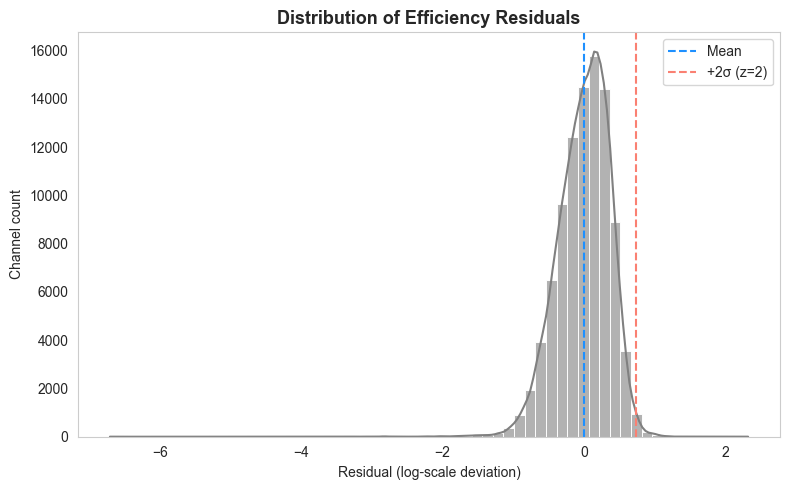

In [5]:
gamma = np.percentile(channels_model["residual"], 97)
plot_residual_distribution(channels_model["residual"])

In [6]:
is_outperformer_mask = channels_model["residual"] > gamma
channel_df["is_outperformer"] = is_outperformer_mask.reindex(channel_df.index, fill_value=False)


In [7]:
outperformers_df = channel_df[channel_df['is_outperformer']]
non_outperformers_df = channel_df=[~channel_df['is_outperformer']]
print(len(outperformers_df))
outperformers_df.head(6)

2831


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,is_outperformer
27568,Music,2012-06-17,UCGnEWsLelLFqMkWcb8s7-nA,孤独なghost,93200,121,88557.0,3.9875,2688.0,0.045015,0.105720,9817455.0,25500.0,845110.0,3881.0,10345.0,0.996371,125,True
29460,People & Blogs,2016-11-05,UCwpAYjmPdYVw6ZNoiul8g2Q,Muhammad Arbaz Offic...,84050,175,95847.0,3.7155,1086.0,0.161142,0.161395,4066492.0,68508.0,303546.0,20696.0,65870.0,0.968095,181,True
30591,Gaming,2019-01-16,UCrDEwtROpcijOFP9uMwz19Q,Parallel Samzyy,79100,40,99714.0,3.7395,284.0,0.140845,0.098866,6788720.0,9521.0,604033.0,11725.0,10072.0,0.979401,51,True
32883,Pets & Animals,2015-12-16,UCkrkMMAyxC9vGNa6ZJYyscg,Takis Shelter - The ...,73600,316,109765.0,5.0415,1411.0,0.223955,0.151517,22679099.0,91716.0,1207584.0,9496.0,104127.0,0.995255,340,True
32943,Gaming,2011-09-27,UC3-8qZ-rZvlSVWwkHoeelCA,TheMythicalSausage,83000,1766,110160.0,5.0940,2952.0,0.598238,0.094543,12100847.0,3513327.0,416318.0,7942.0,87631.0,0.979128,1773,True
33055,Gaming,2019-04-17,UCaH2302aYnmOJH-CWn-Bebg,Military Dave,84100,52,110730.0,4.9860,193.0,0.269430,0.110061,2810462.0,21462.0,304313.0,17771.0,30004.0,0.864303,55,True


## 1st Plot

In [ ]:
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
import base64


# 1. PREPARE DATA
df = channels_model.copy()
df = df[df["subscribers_cc"] > 0].copy()
df["log_subs"] = np.log10(df["subscribers_cc"])

x_min_all, x_max_all = df["log_subs"].min(), df["log_subs"].max()
y_min, y_max = -0.5, df["residual"].max() * 1.1


# 2. PALETTE + COLOR SCALES
PALETTE = {
    "rose":   "#CC6677",
    "indigo": "#332288",
    "sand":   "#DDCC77",
    "green":  "#117733",
    "cyan":   "#88CCEE",
    "wine":   "#882255",
    "teal":   "#44AA99",
    "olive":  "#999933",
    "purple": "#AA4499",
}

# Outperformers: cyan -> indigo (cyan to blue-ish)
OUT_SCALE = [
    [0.0, PALETTE["cyan"]],
    [1.0, PALETTE["indigo"]],
]

# Heatmap: use your palette in a smooth-ish ramp
# (low density -> very light cyan, then teal/olive, then indigo)
HEAT_SCALE = [
    [0.00, "#FFFFFF"],
    [0.15, PALETTE["cyan"]],
    [0.40, PALETTE["teal"]],
    [0.65, PALETTE["olive"]],
    [1.00, PALETTE["indigo"]],
]


# 3. SLIDER CONFIG
step_percentages = [4.6, 3.8, 3.0, 2.2, 1.4, 0.6]
percentile_values = [p / 100 for p in step_percentages]

default_target = 3.0
default_idx = step_percentages.index(default_target) if default_target in step_percentages else 2

# 4. FILTER MAX RANGE (TOP 5%)
max_p = 0.05
min_residual_cutoff = df["residual"].quantile(1 - max_p)
df_max = df[df["residual"] >= min_residual_cutoff].copy().sort_values("residual")


# 5. RENDER HEATMAP ONCE -> EXPORT AS PNG -> BASE64
#    (Preserves Plotly's Histogram2dContour look, but recolored)
# We do this to reduce lag and not have to re-render the heat-map each time the slider changes.
heat_fig = go.Figure()
heat_fig.add_trace(go.Histogram2dContour(
    x=df["log_subs"],
    y=df["residual"],
    colorscale=HEAT_SCALE,
    ncontours=15,
    showscale=False,
    opacity=0.22,
    hoverinfo="skip"
))

heat_fig.update_layout(
    width=1100,
    height=600,
    margin=dict(l=0, r=0, t=0, b=0),
    paper_bgcolor="rgba(0,0,0,0)",
    plot_bgcolor="rgba(0,0,0,0)",
    xaxis=dict(visible=False, range=[x_min_all, x_max_all]),
    yaxis=dict(visible=False, range=[y_min, y_max]),
)

png_bytes = pio.to_image(heat_fig, format="png", scale=2, engine="kaleido")
heat_b64 = base64.b64encode(png_bytes).decode("ascii")
heat_source = f"data:image/png;base64,{heat_b64}"

# 6. PRE-COMPUTE FRAMES (POINTS + THRESHOLD + COUNT TEXT)
frames = []
for p in percentile_values:
    cutoff = df["residual"].quantile(1 - p)
    df_frame = df_max[df_max["residual"] >= cutoff]
    count = len(df_frame)

    frames.append(go.Frame(
        name=f"{p:.4f}",
        traces=[1, 2],  # update only outperformers + threshold
        data=[
            go.Scatter(
                x=df_frame["log_subs"],
                y=df_frame["residual"],
                marker=dict(color=df_frame["residual"]),
                customdata=np.stack([df_frame["name_cc"], df_frame["subscribers_cc"]], axis=-1),
                name=f"Top {p*100:.1f}% ({count:,})"  # legend label (will update with redraw=True)
            ),
            go.Scatter(
                x=[x_min_all, x_max_all],
                y=[cutoff, cutoff]
            )
        ],
        layout=go.Layout(
            annotations=[dict(
                x=0.5, y=-0.27, xref="paper", yref="paper",
                showarrow=False,
                text=f"<b>Outperformers:</b> {count:,}  (Top {p*100:.1f}%)",
                font=dict(size=15)
            )]
        )
    ))

# default state
initial_scatter = frames[default_idx].data[0]
initial_line = frames[default_idx].data[1]
initial_anno = frames[default_idx].layout.annotations[0].text

# 7. BUILD MAIN FIGURE (STATIC HEATMAP IMAGE + ANIMATED POINTS)
fig = go.Figure(frames=frames)

# Static heatmap image anchored in DATA COORDS
fig.update_layout(
    images=[dict(
        source=heat_source,
        xref="x", yref="y",
        x=x_min_all,
        y=y_max,  # top-left
        sizex=(x_max_all - x_min_all),
        sizey=(y_max - y_min),
        sizing="stretch",
        opacity=1.0,
        layer="below",
    )]
)

# Trace 0: Model line at 0
fig.add_trace(go.Scatter(
    x=[x_min_all, x_max_all],
    y=[0, 0],
    mode="lines",
    line=dict(color="black", width=2),
    name="Model",
    hoverinfo="skip"
))

# Trace 1: Outperformers (animated) — cyan->blue scale
fig.add_trace(go.Scatter(
    x=initial_scatter.x,
    y=initial_scatter.y,
    mode="markers",
    marker=dict(
        size=3,
        color=initial_scatter.marker.color,
        colorscale=OUT_SCALE,
        cmin=-0.5, cmax=2.5,
        line=dict(width=0.5, color="DarkSlateGrey"),
        opacity=0.9
    ),
    name=initial_scatter.name,
    customdata=initial_scatter.customdata,
    hovertemplate="<b>%{customdata[0]}</b><br>Subs: %{customdata[1]:,.0f}<br>Residual: %{y:.3f}<extra></extra>",
))

# Trace 2: Threshold (animated) — wine color
fig.add_trace(go.Scatter(
    x=[x_min_all, x_max_all],
    y=initial_line.y,
    mode="lines",
    line=dict(color=PALETTE["wine"], width=2, dash="dot"),
    name="Threshold",
    hoverinfo="skip"
))

# Bottom annotation (replaced by frames)
fig.update_layout(
    annotations=[dict(
        x=0.5, y=-0.27, xref="paper", yref="paper",
        showarrow=False,
        text=initial_anno,
        font=dict(size=15),
    )]
)


# 8. SLIDER
#    redraw=True so the LEGEND text updates (Top X% (count))
#    Safe now because heatmap is a static image.
slider_steps = []
for p in percentile_values:
    slider_steps.append({
        "label": f"{p*100:.1f}%",
        "method": "animate",
        "args": [
            [f"{p:.4f}"],
            {
                "mode": "immediate",
                "frame": {"duration": 0, "redraw": True},   # <- legend updates
                "transition": {"duration": 0}
            }
        ]
    })

fig.update_layout(
    title="<b>Residual Outperformer Detection</b>",
    template="plotly_white",
    width=1100, height=600,
    margin=dict(b=140, t=100),
    legend=dict(orientation="h", y=1.02, x=1, xanchor="right"),
    sliders=[{
        "active": default_idx,
        "currentvalue": {"prefix": "Outperformer Threshold: ", "font": {"size": 16}},
        "pad": {"t": 40},
        "len": 0.9, "x": 0.05, "y": -0.2,
        "steps": slider_steps,
        "transition": {"duration": 0}
    }],
    xaxis=dict(
        title="Subscribers (log scale)",
        range=[x_min_all, x_max_all],
        autorange=False,
        fixedrange=True,
        constrain="domain",
        tickmode="array",
        tickvals=[4, 4.301, 4.699, 5],
        ticktext=["10k", "20k", "50k", "100k"],
    ),
    yaxis=dict(title="Efficiency (Residual)", range=[y_min, y_max]),
    uirevision="lock"
)

fig.show()

# 9. SAVE HTML
pio.write_html(fig, "outperformers_plot.html", auto_play=False)


C:\Users\Jon\AppData\Local\Temp\ipykernel_2104\2729034618.py:88: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.


